In [4]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [5]:
# ==============================================================================
# 1. LOAD CHAMPION DATASET & HMM (KEEPING CLUSTER_ID INTACT)
# ==============================================================================
print("Loading Top 200 Features and HMM Features...")

X_top200 = pd.read_parquet('../data/processed/features_final_top200.parquet')
X_hmm = pd.read_parquet('../data/processed/features_hmm.parquet')

# Join by index (ID)
X_combined = X_top200.join(X_hmm)
X_combined.columns = X_combined.columns.str.replace(r'[^\w\s]', '_', regex=True)

# Ensure Cluster_ID exists and is treated as a numerical category for splitting
if 'Cluster_ID' not in X_combined.columns:
    raise ValueError("Cluster_ID is missing! Make sure your Top 200 dataset includes it.")

# Load target variable
y_train = pd.read_parquet('../data/raw/y_train.parquet')
y = y_train.loc[X_combined.index]['structural_breakpoint']

print(f"Global dataset shape: {X_combined.shape}")

Loading Top 200 Features and HMM Features...
Global dataset shape: (10001, 207)


In [6]:
# ==============================================================================
# 2. DIVIDE AND CONQUER: TRAIN EXPERT ENSEMBLES PER CLUSTER
# ==============================================================================
# We will store the Out-Of-Fold (OOF) predictions for the entire dataset here
# to calculate the Global ROC AUC at the end.
oof_predictions = pd.Series(index=y.index, dtype=float)

unique_clusters = sorted(X_combined['Cluster_ID'].dropna().unique())
print(f"\nFound {len(unique_clusters)} unique clusters. Beginning Specialist Training...\n")

for cluster in unique_clusters:
    print("="*60)
    print(f"TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: {cluster}")
    print("="*60)
    
    # 1. Isolate the data for this specific cluster
    X_cluster = X_combined[X_combined['Cluster_ID'] == cluster].copy()
    y_cluster = y.loc[X_cluster.index]
    
    # 2. Drop the Cluster_ID column (it has zero variance now and we don't need OHE)
    X_cluster = X_cluster.drop(columns=['Cluster_ID'])
    
    print(f"Cluster Size: {len(X_cluster)} series | Features: {X_cluster.shape[1]}")
    
    # 3. Calculate local imbalance ratio for this specific domain
    if (y_cluster == 1).sum() == 0 or (y_cluster == 0).sum() == 0:
        print(f"WARNING: Cluster {cluster} only has one class! Skipping CV and predicting 0.")
        oof_predictions.loc[X_cluster.index] = 0.0
        continue
        
    local_imbalance = float((y_cluster == 0).sum() / (y_cluster == 1).sum())
    print(f"Local Imbalance Ratio (False/True): {local_imbalance:.4f}")
    
    # 4. Define the Local Holy Trinity
    xgb_model = xgb.XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5, # Slightly shallower to avoid overfitting smaller clusters
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=local_imbalance, 
        eval_metric='auc', random_state=42, n_jobs=-1
    )
    
    lgb_model = lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5, num_leaves=25,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=local_imbalance,
        random_state=42, n_jobs=-1, verbose=-1
    )
    
    cat_model = CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=5,
        scale_pos_weight=local_imbalance, eval_metric='AUC',
        random_state=42, verbose=0, thread_count=-1
    )
    
    # Local Ensemble
    local_ensemble = VotingClassifier(
        estimators=[('xgb', xgb_model), ('lgb', lgb_model), ('cat', cat_model)],
        voting='soft', n_jobs=1 
    )
    
    # 5. Cross-Validate within the cluster
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Get Out-Of-Fold probability predictions
    preds_proba = cross_val_predict(
        local_ensemble, X_cluster, y_cluster, 
        cv=cv_strategy, method='predict_proba', n_jobs=1
    )[:, 1] # Index 1 gets the probability of class 1 (Breakpoint)
    
    # Store predictions in the global array
    oof_predictions.loc[X_cluster.index] = preds_proba
    
    # Calculate and print Local ROC AUC
    local_auc = roc_auc_score(y_cluster, preds_proba)
    print(f"--> Local ROC AUC for Cluster {cluster}: {local_auc:.4f}\n")


Found 7 unique clusters. Beginning Specialist Training...

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: -1
Cluster Size: 30 series | Features: 206
Local Imbalance Ratio (False/True): 2.3333
--> Local ROC AUC for Cluster -1: 0.7196

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: 0
Cluster Size: 626 series | Features: 206
Local Imbalance Ratio (False/True): 2.4778
--> Local ROC AUC for Cluster 0: 0.9366

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: 1
Cluster Size: 7984 series | Features: 206
Local Imbalance Ratio (False/True): 2.4310
--> Local ROC AUC for Cluster 1: 0.7692

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: 2
Cluster Size: 52 series | Features: 206
Local Imbalance Ratio (False/True): 2.2500
--> Local ROC AUC for Cluster 2: 0.5955

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: 3
Cluster Size: 579 series | Features: 206
Local Imbalance Ratio (False/True): 2.3468
--> Local ROC AUC for Cluster 3: 0.7729

TRAINING SPECIALIST ENSEMBLE FOR CLUSTER: 4
Cluster Size: 181 series | Features: 206
Local Imb

In [7]:
# ==============================================================================
# 3. GLOBAL EVALUATION (COMBINING ALL SPECIALISTS)
# ==============================================================================
print("\n" + "="*60)
print("FINAL GLOBAL EVALUATION (ALL CLUSTERS COMBINED)")
print("Target to beat: 0.7829 (Single Global Ensemble)")
print("="*60)

# Calculate the Global ROC AUC using the combined Out-Of-Fold predictions
global_auc = roc_auc_score(y, oof_predictions)
print(f"\nGLOBAL ROC AUC: {global_auc:.4f}")

# Convert probabilities to binary labels for the Classification Report
y_pred_global = (oof_predictions >= 0.5).astype(int)

print("\nGLOBAL CLASSIFICATION REPORT:")
print(classification_report(y, y_pred_global, digits=4))


FINAL GLOBAL EVALUATION (ALL CLUSTERS COMBINED)
Target to beat: 0.7829 (Single Global Ensemble)

GLOBAL ROC AUC: 0.7651

GLOBAL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False     0.8178    0.8813    0.8484      7092
        True     0.6431    0.5215    0.5759      2909

    accuracy                         0.7766     10001
   macro avg     0.7305    0.7014    0.7122     10001
weighted avg     0.7670    0.7766    0.7691     10001



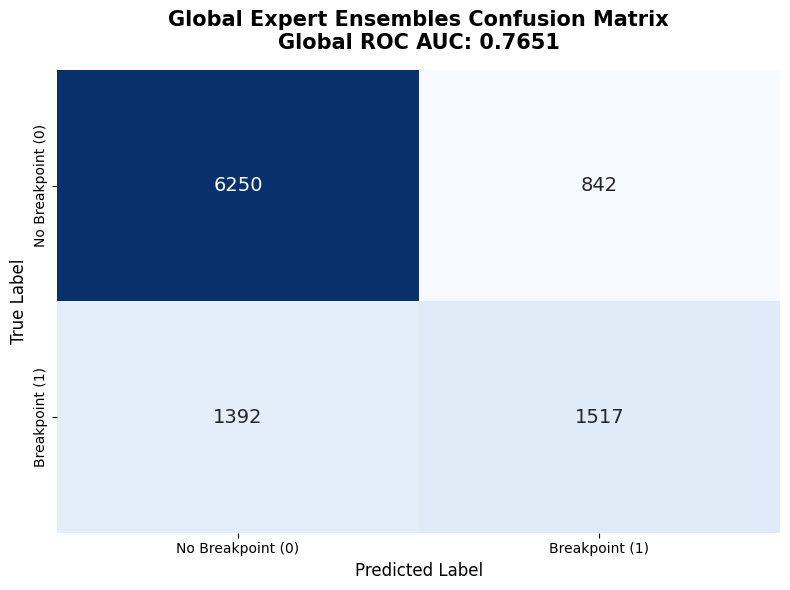

In [8]:
# ==============================================================================
# 4. GLOBAL CONFUSION MATRIX VISUALIZATION
# ==============================================================================
cm = confusion_matrix(y, y_pred_global)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title(f'Global Expert Ensembles Confusion Matrix\nGlobal ROC AUC: {global_auc:.4f}', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()